### Основы машинного обучения
### Простая регрессионная модель
1. Загрузка и первичный анализ данных
2. Выбор целевой переменной (y) и признаков (X) 
3. Предварительная обработка данных
4. Разделение выборки на обучающую и тестовую
5. Обучение модели
6. Получение предсказаний и оценка качества
7. Анализ результата, коэффициентов модели

### Задача:
0. Установить библиотеку scikit-learn
1. Скачать данные с Kaggle
2. Сделать модель линейное регрессии по алгоритму

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df_raw = pd.read_csv('../data/raw/bedtime_screentime_sleep_debt.csv')

In [5]:
df_raw

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [ ]:
df_raw['occupation_type'].value_counts()

In [9]:
# y 
# total_sleep_hours
# X:
# age
# gender
# chronotype
# bedtime_phone_minutes
# caffeine_post_5pm_mg
# physical_activity_min

In [10]:
df = df_raw[['total_sleep_hours', 'age', 'gender', 'chronotype', 'bedtime_phone_minutes', 'caffeine_post_5pm_mg', 'physical_activity_min']].copy()

In [11]:
df

,total_sleep_hours,age,gender,chronotype,bedtime_phone_minutes,caffeine_post_5pm_mg,physical_activity_min
0,3.20,29,Female,Intermediate,179,0,21
1,4.06,58,Female,Intermediate,163,92,72
2,3.20,41,Female,Night Owl,100,45,23
3,6.99,36,Non-Binary,Intermediate,34,97,49
4,4.58,23,Female,Intermediate,27,0,38
...,...,...,...,...,...,...,...
8495,5.57,61,Female,Night Owl,18,60,74
8496,3.99,64,Male,Night Owl,138,0,58
8497,7.58,34,Male,Intermediate,56,94,33
8498,3.20,23,Male,Night Owl,165,0,52


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   total_sleep_hours      8500 non-null   float64
 1   age                    8500 non-null   int64  
 2   gender                 8500 non-null   object 
 3   chronotype             8500 non-null   object 
 4   bedtime_phone_minutes  8500 non-null   int64  
 5   caffeine_post_5pm_mg   8500 non-null   int64  
 6   physical_activity_min  8500 non-null   int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 465.0+ KB


In [16]:
df.isnull().sum()

total_sleep_hours        0
age                      0
gender                   0
chronotype               0
bedtime_phone_minutes    0
caffeine_post_5pm_mg     0
physical_activity_min    0
dtype: int64

In [20]:
df_raw.duplicated().sum()

np.int64(0)

In [21]:
df_processed = pd.get_dummies(
    df, 
    columns=['gender', 'chronotype'], 
    drop_first=True,
)

In [22]:
df_processed

,total_sleep_hours,age,bedtime_phone_minutes,caffeine_post_5pm_mg,physical_activity_min,gender_Male,gender_Non-Binary,chronotype_Morning Lark,chronotype_Night Owl
0,3.20,29,179,0,21,False,False,False,False
1,4.06,58,163,92,72,False,False,False,False
2,3.20,41,100,45,23,False,False,False,True
3,6.99,36,34,97,49,False,True,False,False
4,4.58,23,27,0,38,False,False,False,False
...,...,...,...,...,...,...,...,...,...
8495,5.57,61,18,60,74,False,False,False,True
8496,3.99,64,138,0,58,True,False,False,True
8497,7.58,34,56,94,33,True,False,False,False
8498,3.20,23,165,0,52,True,False,False,True


In [23]:
df_processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   total_sleep_hours        8500 non-null   float64
 1   age                      8500 non-null   int64  
 2   bedtime_phone_minutes    8500 non-null   int64  
 3   caffeine_post_5pm_mg     8500 non-null   int64  
 4   physical_activity_min    8500 non-null   int64  
 5   gender_Male              8500 non-null   bool   
 6   gender_Non-Binary        8500 non-null   bool   
 7   chronotype_Morning Lark  8500 non-null   bool   
 8   chronotype_Night Owl     8500 non-null   bool   
dtypes: bool(4), float64(1), int64(4)
memory usage: 365.4 KB


In [24]:
y = df_processed['total_sleep_hours']
X = df_processed.drop('total_sleep_hours', axis=1)

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=123
)

In [26]:
X_train

,age,bedtime_phone_minutes,caffeine_post_5pm_mg,physical_activity_min,gender_Male,gender_Non-Binary,chronotype_Morning Lark,chronotype_Night Owl
2571,53,53,0,20,True,False,False,True
5546,21,39,128,56,False,False,True,False
7089,20,54,0,83,False,False,True,False
5835,36,57,82,34,True,False,False,False
7623,39,51,0,27,False,False,False,False
...,...,...,...,...,...,...,...,...
7382,63,78,0,35,False,False,False,False
7763,40,73,129,37,True,False,False,True
5218,25,67,0,54,False,False,False,True
1346,28,97,0,18,True,False,False,True


In [27]:
y_train

2571    3.79
5546    8.49
7089    7.72
5835    6.43
7623    5.17
        ... 
7382    6.09
7763    4.40
5218    4.26
1346    4.05
3582    6.20
Name: total_sleep_hours, Length: 6800, dtype: float64

In [28]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
predictions = model.predict(X_test)

In [30]:
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

In [31]:
df_processed['total_sleep_hours'].describe()

count    8500.000000
mean        6.266209
std         1.446258
min         3.200000
25%         5.240000
50%         6.330000
75%         7.350000
max         9.800000
Name: total_sleep_hours, dtype: float64

In [32]:
print(f"""
Метрики качества:
MAE: {mae:.2f}
RMSE: {rmse:.2f}
R^2: {r2:.2f}
""")


Метрики качества:
MAE: 0.64
RMSE: 0.81
R^2: 0.69



In [33]:
coeffs = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])

In [38]:
df['chronotype'].value_counts()

chronotype
Intermediate    3880
Night Owl       2455
Morning Lark    2165
Name: count, dtype: int64

In [37]:
coeffs.sort_values('Coefficient')

,Coefficient
chronotype_Night Owl,-1.453371
bedtime_phone_minutes,-0.022116
gender_Non-Binary,-0.018126
caffeine_post_5pm_mg,-0.001127
physical_activity_min,-0.000133
age,0.001079
gender_Male,0.007216
chronotype_Morning Lark,0.941869


In [39]:
model.intercept_

np.float64(7.76216370867498)

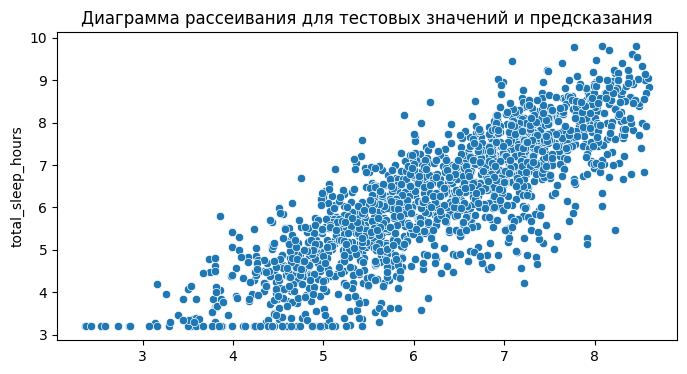

In [40]:
plt.figure(figsize=(8,4)) # Размер графика
plt.title('Диаграмма рассеивания для тестовых значений и предсказания') # Заголовок
ax = sns.scatterplot(
    x=predictions,
    y=y_test,
)
plt.show()